In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

Set 2. Question 3. PART A

In [2]:
data_file = 'C:/Users/user/OneDrive/Desktop/data.txt'

output_directory = 'split_data'
os.makedirs(output_directory, exist_ok=True)

with open(data_file, 'r') as file:
    input_data = np.loadtxt(file)

chunk_size = len(input_data) // 100
for i in range(100):
    start = i * chunk_size
    end = start + chunk_size
    output_file = os.path.join(output_directory, f'data_{i + 1}.txt')
    np.savetxt(output_file, input_data[start:end], fmt='%f')


Set 2. Question 3. PART B

In [3]:
output_directories = [os.path.join(output_directory, f'directory_{i + 1}') for i in range(100)]
for directory in output_directories:
    os.makedirs(directory, exist_ok=True)

for i, directory in enumerate(output_directories):
    input_file = os.path.join(output_directory, f'data_{i + 1}.txt')
    output_file = os.path.join(directory, f'data_{i + 1}.txt')
    os.rename(input_file, output_file)

Set 2. Question 3. PART C

In [4]:
deltas = [0.1, 0.01, 0.001]
pdf_data = []

for directory in output_directories:
    pdf_values = []
    files = os.listdir(directory)
    for file in files:
        file_path = os.path.join(directory, file)
        with open(file_path, 'r') as file:
            data = np.loadtxt(file)
        pdf = np.convolve(data, np.ones(int(1 / deltas[0])) / int(1 / deltas[0]), mode='same')
        pdf_values.append(pdf)
    pdf_data.append(pdf_values)

Set 2. Question 3. PART D

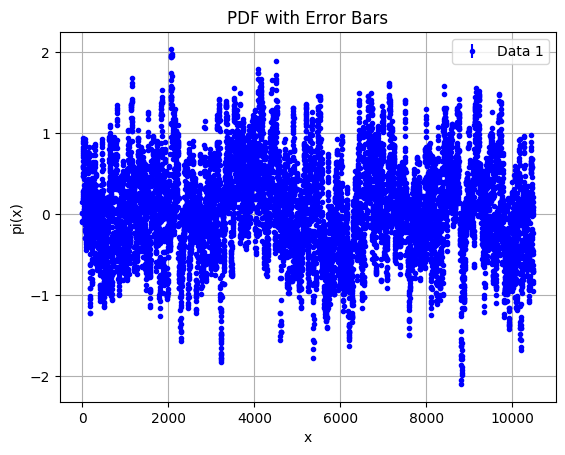

In [5]:
m = len(deltas)
n = len(pdf_data[0][0])
sigma_m = np.std(pdf_data, axis=0) / np.sqrt(n)

for i, pdf_values in enumerate(pdf_data):
    if i < len(sigma_m):  # Check if index is within the bounds of sigma_m
        plt.errorbar(np.arange(len(pdf_values[0])), np.mean(pdf_values, axis=0), yerr=sigma_m[i], fmt='b.', label=f'Data {i + 1}')

plt.xlabel('x')
plt.ylabel('pi(x)')
plt.title('PDF with Error Bars')
plt.legend()
plt.grid(True)
plt.show()

Set 2. Question 3. PART E

In [6]:
sigmas = [2.0, 0.2]
smoothed_pdf_data = []

for new_pdf_values in pdf_data:
    smoothed_pdf_values = []
    for pdf in new_pdf_values:
        smoothed_pdf = np.convolve(pdf, np.exp(-np.arange(-3, 4) ** 2 / (2 * sigmas[0])) / np.sqrt(2 * np.pi * sigmas[0]), mode='same')
        smoothed_pdf_values.append(smoothed_pdf)
    smoothed_pdf_data.append(smoothed_pdf_values)

Set 2. Question 3. PART F

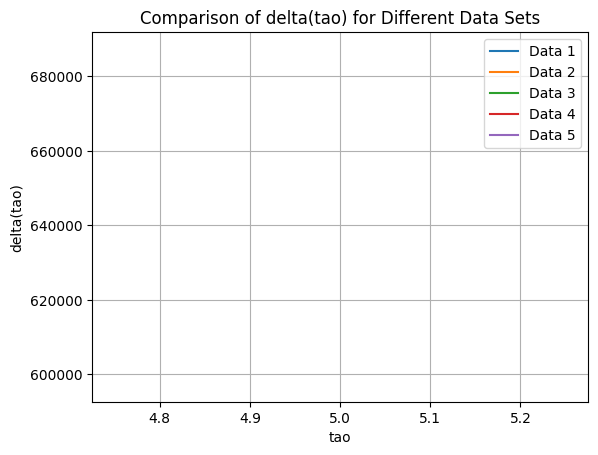

In [8]:
tao = np.arange(5, 6)
delta_tao = []

for pdf_values in smoothed_pdf_data:
    delta_tao_values = []
    for pdf in pdf_values:
        delta = np.abs(np.convolve(pdf, np.roll(pdf, tao)) - np.convolve(pdf, pdf))
        delta_tao_values.append(np.trapz(delta, dx=1))
    delta_tao.append(delta_tao_values)

delta_tao = np.array(delta_tao)

for i in range(min(5, len(delta_tao))):
    plt.plot(tao, delta_tao[i], label=f'Data {i + 1}')

plt.xlabel('tao')
plt.ylabel('delta(tao)')
plt.title('Comparison of delta(tao) for Different Data Sets')
plt.legend()
plt.grid(True)
plt.show()